<a href="https://colab.research.google.com/github/kamij45/Autonomous-Navigation/blob/main/Reinforcement_Learning_Autonomous_Navigation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q gymnasium

In [2]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

Creating the enviroment we will use

In [3]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=False, render_mode="rgb_array")
state, info = env.reset()

print("Starting state:", state)
print("Number of states:", env.observation_space.n)
print("Number of actions:", env.action_space.n)
print("Action Meanings:", {
    0: "LEFT",
    1: "DOWN",
    2: "RIGHT",
    3: "UP"
})

Starting state: 0
Number of states: 16
Number of actions: 4
Action Meanings: {0: 'LEFT', 1: 'DOWN', 2: 'RIGHT', 3: 'UP'}


/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


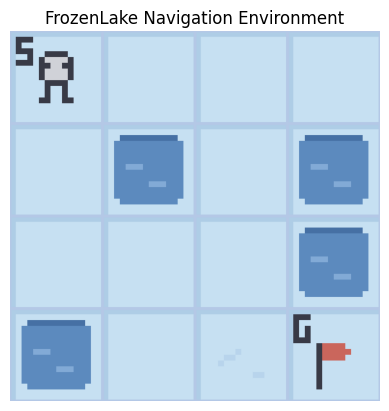

In [4]:
plt.imshow(env.render())
plt.axis("off")
plt.title("FrozenLake Navigation Environment")
plt.show()

Creating the Q table

In [5]:
q_table = np.zeros((env.observation_space.n, env.action_space.n))
print("Q-table shape:", q_table.shape)
print(q_table)

Q-table shape: (16, 4)
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [6]:
def run_random_agent(env, episodes=1000, max_steps=100):
  successes = 0
  total_rewards = []

  for episode in range(episodes):
    state, info = env.reset()
    episode_reward = 0

    for step in range(max_steps):
      action = env.action_space.sample()
      next_state, reward, terminated, truncated, info = (env.step(action))

      episode_reward += reward
      state = next_state

      if terminated or truncated:
        break

    total_rewards.append(episode_reward)
    if episode_reward > 0:
      successes += 1

  success_rate = (successes / episodes) * 100
  average_reward = np.mean(total_rewards)

  return success_rate, average_reward

random_success, random_reward = run_random_agent(env)

print(f"Random Agent Success Rate: {random_success:.2f}%")
print(f"Random Agent Average Reward: {random_reward:.3f}")

Random Agent Success Rate: 1.40%
Random Agent Average Reward: 0.014


In [7]:
q_table = np.zeros((env.observation_space.n, env.action_space.n))

In [8]:
def best_action(q_table, state):
  q_values = q_table[state]
  return np.argmax(q_table[state])

Q-table Learning

In [9]:
alpha = 0.1
gamma = 0.99
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.999

episodes = 10000
max_steps = 100

training_rewards =[]
training_successes =[]

for episode in range (episodes):
  state, info = env.reset()
  total_reward = 0

  for step in range(max_steps):
    if np.random.random() < epsilon:
      action = env.action_space.sample()
    else:
      action = np.argmax(q_table[state])

    next_state, reward, terminated, truncated, info = (env.step(action))

    target = reward + gamma * np.max(q_table[next_state]) * (not terminated)

    q_table[state, action] += alpha * (target - q_table[state, action])

    state = next_state
    total_reward += reward

    if terminated or truncated:
      break

  training_rewards.append(total_reward)
  training_successes.append(total_reward > 0)

  epsilon = max(epsilon_min, epsilon * epsilon_decay)
print("Training Complete")
print("Final Q-table:")
print(np.round(q_table, 2))

Training Complete
Final Q-table:
[[0.94 0.95 0.93 0.94]
 [0.94 0.   0.49 0.68]
 [0.6  0.82 0.01 0.23]
 [0.11 0.   0.   0.  ]
 [0.95 0.96 0.   0.94]
 [0.   0.   0.   0.  ]
 [0.   0.98 0.   0.4 ]
 [0.   0.   0.   0.  ]
 [0.96 0.   0.97 0.95]
 [0.96 0.98 0.98 0.  ]
 [0.97 0.99 0.   0.97]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.81 0.99 0.72]
 [0.98 0.99 1.   0.98]
 [0.   0.   0.   0.  ]]


Comparing Both Agents and evaluating the trained(q-table) agent

In [10]:
def evaluate_q_agent(env, q_table, episodes=1000, max_steps = 100):
  successes = 0
  total_rewards = []

  for episode in range(episodes):
    state, info = env.reset()
    total_reward = 0

    for step in range(max_steps):
      action = np.argmax(q_table[state])
      next_state, reward, terminated, truncated, info = (env.step(action))

      total_reward += reward
      state = next_state

      if terminated or truncated:
        break

    total_rewards.append(total_reward)
    if total_reward > 0:
      successes += 1

  success_rate = (successes / episodes) * 100
  average_reward = np.mean(total_rewards)

  return success_rate , average_reward
q_success, q_reward = evaluate_q_agent(env, q_table)

print(f"Q-learning Agent Success Rate: {q_success:.2f}%")
print(f"Random Agent Success Rate: {random_success:.2f}%")
print(f"Q-learning Agent Average Reward: {q_reward:.3f}")
print(f"Random Agent Average Reward: {random_reward:.3f}")

Q-learning Agent Success Rate: 100.00%
Random Agent Success Rate: 1.40%
Q-learning Agent Average Reward: 1.000
Random Agent Average Reward: 0.014


Visualizing the comparison

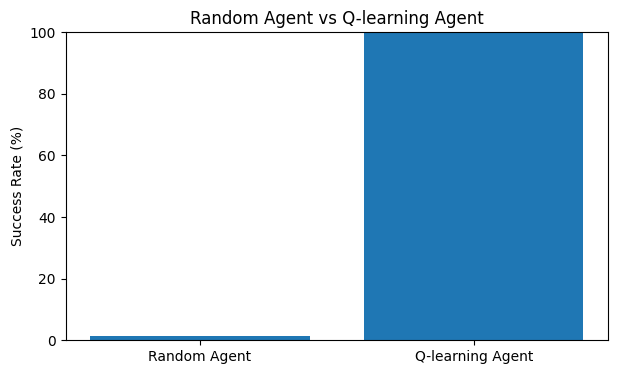

In [11]:
labels = ["Random Agent", "Q-learning Agent"]
success_rates = [random_success, q_success]

plt.figure(figsize=(7,4))
plt.bar(labels, success_rates)
plt.ylabel("Success Rate (%)")
plt.title("Random Agent vs Q-learning Agent")
plt.ylim(0, 100)
plt.show()